# Desafio PTCG: classificacao de desempenho

Este projeto usa episodios reais do desafio PTCG da The Pokemon Company.

O objetivo e prever se um episodio tera desempenho **Baixo**, **Medio** ou **Alto**.
A variavel alvo e criada pelos tercis da pontuacao media (`avg_score`). Os campos usados para
prever nao incluem `avg_score`, evitando vazamento da variavel alvo.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(raiz / "data" / "dataset.csv")
df.head()

,episode_id,create_time,avg_score,min_score,sum_score,agent_count,size_bytes
0,127431692,2026-11-21T07:49:31.4955121,1554.453467,1543.743146,3108.906934,2,7516540
1,127430377,2026-11-21T07:29:29.4398667,1554.453467,1538.721743,3108.906934,2,9151510
2,127437264,2026-11-21T09:21:30.1469793,1553.808862,1548.008295,3107.617724,2,8243598
3,127433081,2026-11-21T08:13:33.5056120,1553.547957,1534.760519,3107.095914,2,12428443
4,127440896,2026-11-21T10:21:40.3213781,1552.844352,1538.493978,3105.688705,2,14394601


In [2]:
print("Formato:", df.shape)
print("\nValores ausentes:")
print(df.isna().sum())
print("\nTipos:")
print(df.dtypes)
print("\nEstatisticas:")
print(df.describe())

Formato: (1640, 7)

Valores ausentes:
episode_id     0
create_time    0
avg_score      0
min_score      0
sum_score      0
agent_count    0
size_bytes     0
dtype: int64

Tipos:
episode_id       int64
create_time        str
avg_score      float64
min_score      float64
sum_score      float64
agent_count      int64
size_bytes       int64
dtype: object

Estatisticas:
         episode_id    avg_score    min_score    sum_score  agent_count  \
count  1.640000e+03  1640.000000  1640.000000  1640.000000       1640.0   
mean   1.274464e+08  1315.788046  1290.637641  2631.576091          2.0   
std    2.478026e+04    93.241476    97.580558   186.482952          0.0   
min    1.274036e+08  1213.367269   883.329108  2426.734539          2.0   
25%    1.274259e+08  1243.907401  1224.587249  2487.814803          2.0   
50%    1.274457e+08  1281.274991  1260.393511  2562.549982          2.0   
75%    1.274681e+08  1365.784566  1340.163247  2731.569133          2.0   
max    1.274897e+08  1554.453467

In [3]:
df["create_time"] = pd.to_datetime(df["create_time"], utc=True)
df["hora"] = df["create_time"].dt.hour

df["categoria_desempenho"] = pd.qcut(
    df["avg_score"],
    q=3,
    labels=["Baixo", "Medio", "Alto"],
)

print("Contagem da variavel alvo:")
print(df["categoria_desempenho"].value_counts().sort_index())

Contagem da variavel alvo:
categoria_desempenho
Baixo    547
Medio    546
Alto     547
Name: count, dtype: int64


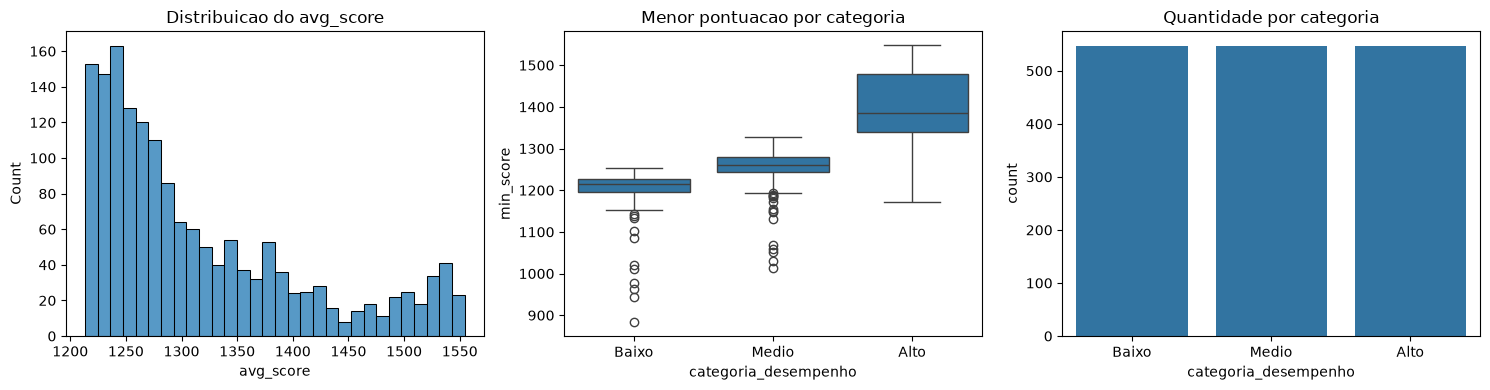

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["avg_score"], bins=30, ax=axes[0])
axes[0].set_title("Distribuicao do avg_score")

sns.boxplot(data=df, x="categoria_desempenho", y="min_score", ax=axes[1])
axes[1].set_title("Menor pontuacao por categoria")

sns.countplot(data=df, x="categoria_desempenho", ax=axes[2])
axes[2].set_title("Quantidade por categoria")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier

X = df[["min_score", "sum_score", "size_bytes", "hora"]]
y = df["categoria_desempenho"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=77,
    stratify=y,
)

print("Treino:", X_treino.shape)
print("Teste:", X_teste.shape)

Treino: (1312, 4)
Teste: (328, 4)


In [6]:
preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), X.columns.tolist()),
    ]
)

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    learning_rate_init=0.001,
    max_iter=500,
    random_state=77,
    early_stopping=True,
)

pipeline = Pipeline([
    ("preprocessamento", preprocessador),
    ("mlp", mlp),
])

pipeline.fit(X_treino, y_treino)
print("Treinamento concluido")

Treinamento concluido


In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_previsto = pipeline.predict(X_teste)

print("Acuracia:", accuracy_score(y_teste, y_previsto))
print("\nRelatorio:")
print(classification_report(y_teste, y_previsto))
print("\nMatriz de confusao:")
print(confusion_matrix(y_teste, y_previsto))

Acuracia: 0.9786585365853658

Relatorio:
              precision    recall  f1-score   support

        Alto       0.98      0.98      0.98       109
       Baixo       0.99      0.98      0.99       110
       Medio       0.96      0.97      0.97       109

    accuracy                           0.98       328
   macro avg       0.98      0.98      0.98       328
weighted avg       0.98      0.98      0.98       328


Matriz de confusao:
[[107   0   2]
 [  0 108   2]
 [  2   1 106]]


In [8]:
import joblib

modelo_path = raiz / "models" / "modelo_mlp.joblib"
modelo_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, modelo_path)
print("Modelo salvo em:", modelo_path)

Modelo salvo em: C:\Users\marce\Desktop\atvycaro-2-marcelo\am-at2-redes-neurais\models\modelo_mlp.joblib
